# 1.1 · IA, machine learning y deep learning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MaxRobles1/deep-learning-equation-to-code/blob/main/topics/01-introduction/1.1-ai-ml-dl.ipynb)

**Objetivos.** Al terminar esta lección podrás:
1. Distinguir inteligencia artificial, machine learning y deep learning, y ubicar cada uno
   dentro del otro.
2. Explicar la diferencia entre programar reglas y aprenderlas a partir de datos.
3. Reconocer los tres tipos de aprendizaje: supervisado, no supervisado y por refuerzo.
4. Expresar "aprender" como un problema de optimización y resolver un caso sencillo en NumPy
   y en PyTorch.

**Prerrequisitos.** La ecuación de una recta y Python básico.

Preparamos el entorno: bibliotecas, semillas y formato de impresión.

In [1]:
import os
from itertools import pairwise

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Ellipse, FancyBboxPatch

QUICK_MODE = os.environ.get("QUICK_MODE") == "1"  # set by CI; this lesson is fast either way
SEED = 0
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.dpi"] = 90

## 1 · Intuición

### Uno dentro del otro

Los tres términos se usan a menudo como sinónimos, pero no lo son:

- **Inteligencia artificial (IA):** el campo que busca que una máquina realice tareas que
  asociamos con la inteligencia, como razonar, planear, percibir o comunicarse. No siempre
  aprende: un sistema experto con reglas escritas a mano o un programa de ajedrez que solo
  busca jugadas también son IA.
- **Machine learning (ML) o aprendizaje máquina:** la parte de la IA en la que el sistema
  **mejora a partir de datos** en lugar de seguir reglas escritas por una persona.
- **Deep learning (DL) o aprendizaje profundo:** la parte del ML que usa **redes neuronales
  con varias capas**, capaces de aprender por sí mismas qué características de los datos
  son útiles.

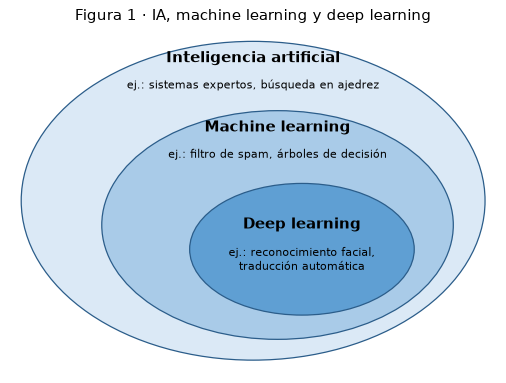

In [2]:
fig, ax = plt.subplots(figsize=(7, 5))
layers = [
    (
        (0.50, 0.50),
        0.95,
        0.92,
        "#dbe9f6",
        "Inteligencia artificial",
        0.90,
        "ej.: sistemas expertos, búsqueda en ajedrez",
    ),
    (
        (0.55, 0.43),
        0.72,
        0.66,
        "#a9cbe8",
        "Machine learning",
        0.70,
        "ej.: filtro de spam, árboles de decisión",
    ),
    (
        (0.60, 0.36),
        0.46,
        0.38,
        "#5f9fd3",
        "Deep learning",
        0.42,
        "ej.: reconocimiento facial,\ntraducción automática",
    ),
]
for center, width, height, color, title, y_title, example in layers:
    ax.add_patch(Ellipse(center, width, height, facecolor=color, edgecolor="#2b5d8a"))
    ax.text(center[0], y_title, title, ha="center", fontsize=12, fontweight="bold")
    ax.text(center[0], y_title - 0.05, example, ha="center", va="top", fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("Figura 1 · IA, machine learning y deep learning")
plt.show()

### Programar reglas o aprenderlas

En la **programación tradicional**, una persona escribe las reglas y la computadora las
aplica a los datos para producir respuestas. En el **machine learning** el camino se invierte:
la computadora recibe datos junto con sus respuestas correctas y **descubre las reglas**.

Piensa en un filtro de correo no deseado. Escribir todas las reglas a mano ("si contiene la
palabra *gratis*, si viene de tal dominio…") es interminable y fácil de burlar. Con machine
learning, el sistema analiza miles de correos ya marcados como deseados o no deseados y
aprende por sí mismo qué los distingue.

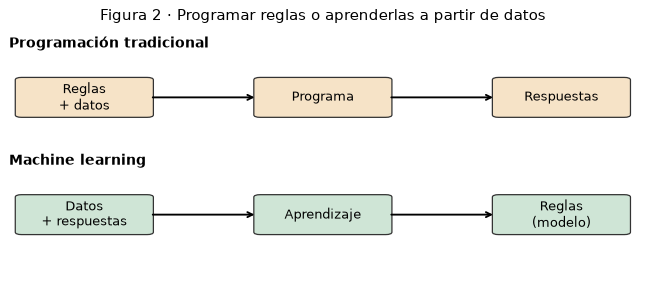

In [3]:
def draw_flow(ax, y, boxes, color):
    """Draw a left-to-right chain of labeled boxes connected by arrows."""
    xs = np.linspace(0.12, 0.88, len(boxes))
    for x, label in zip(xs, boxes, strict=True):
        ax.add_patch(
            FancyBboxPatch(
                (x - 0.1, y - 0.07),
                0.2,
                0.14,
                boxstyle="round,pad=0.01",
                facecolor=color,
                edgecolor="#333333",
            )
        )
        ax.text(x, y, label, ha="center", va="center", fontsize=10)
    for x_from, x_to in pairwise(xs):
        ax.annotate(
            "",
            xy=(x_to - 0.105, y),
            xytext=(x_from + 0.105, y),
            arrowprops={"arrowstyle": "->", "lw": 1.5},
        )


fig, ax = plt.subplots(figsize=(9, 3.6))
draw_flow(ax, 0.72, ["Reglas\n+ datos", "Programa", "Respuestas"], "#f6e3c7")
draw_flow(ax, 0.25, ["Datos\n+ respuestas", "Aprendizaje", "Reglas\n(modelo)"], "#cfe5d6")
ax.text(0.0, 0.92, "Programación tradicional", fontsize=11, fontweight="bold")
ax.text(0.0, 0.45, "Machine learning", fontsize=11, fontweight="bold")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("Figura 2 · Programar reglas o aprenderlas a partir de datos")
plt.show()

### Tres formas de aprender

| Tipo | Qué recibe | Ejemplo | Dónde lo verás |
|---|---|---|---|
| **Supervisado** | Ejemplos con su respuesta correcta | Reconocer el dígito de una imagen | Temas 1 a 7 |
| **No supervisado** | Solo ejemplos, sin respuesta | Comprimir datos o generar imágenes nuevas | Temas 8 y 9 |
| **Por refuerzo** | Recompensas por sus acciones | Aprender a jugar un videojuego | Tema 10 |

### Por qué "profundo"

En el machine learning clásico, una persona suele diseñar a mano las **características** que
el modelo usa: para reconocer un rostro, por ejemplo, medir distancias entre los ojos o la
forma de la nariz. El deep learning aprende esas características por sí mismo, en capas: las
primeras detectan patrones simples, como bordes, y las siguientes los combinan en formas y
después en objetos completos. Esa sucesión de capas es lo "profundo".

### Un poco de historia

La figura 3 resume algunos hitos. La idea de la neurona artificial tiene más de 80 años; lo
que cambió en la última década fue la combinación de muchos datos, computadoras más potentes
(en especial las GPU) y mejores técnicas de entrenamiento.

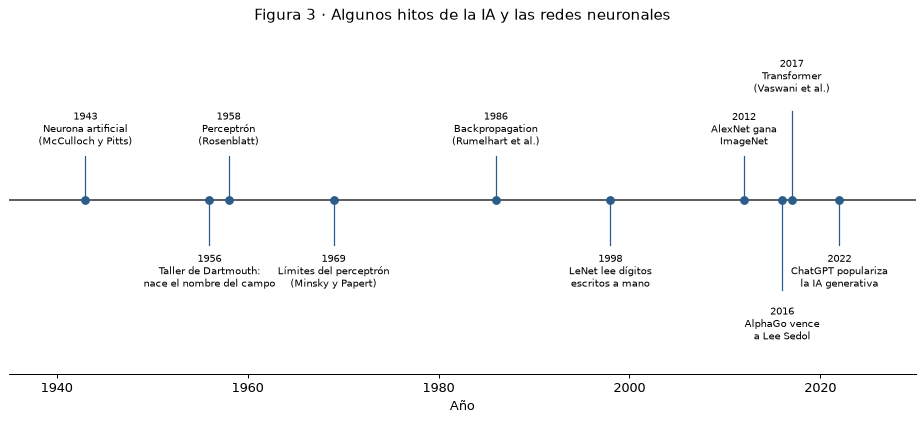

In [4]:
milestones = [
    (1943, "Neurona artificial\n(McCulloch y Pitts)"),
    (1956, "Taller de Dartmouth:\nnace el nombre del campo"),
    (1958, "Perceptrón\n(Rosenblatt)"),
    (1969, "Límites del perceptrón\n(Minsky y Papert)"),
    (1986, "Backpropagation\n(Rumelhart et al.)"),
    (1998, "LeNet lee dígitos\nescritos a mano"),
    (2012, "AlexNet gana\nImageNet"),
    (2016, "AlphaGo vence\na Lee Sedol"),
    (2017, "Transformer\n(Vaswani et al.)"),
    (2022, "ChatGPT populariza\nla IA generativa"),
]
# Label height for each milestone: alternating sides, two levels where years are close.
levels = [1, -1, 1, -1, 1, -1, 1, -2, 2, -1]

fig, ax = plt.subplots(figsize=(13, 5))
ax.axhline(0, color="#555555", linewidth=1.5)
for (year, label), level in zip(milestones, levels, strict=True):
    height = 0.7 * level
    ax.plot([year, year], [0, height * 0.85], color="#2b5d8a", linewidth=1)
    ax.plot(year, 0, "o", color="#2b5d8a")
    ax.text(
        year,
        height,
        f"{year}\n{label}",
        ha="center",
        va="bottom" if height > 0 else "top",
        fontsize=8,
    )
ax.set_xlim(1935, 2030)
ax.set_ylim(-2.3, 2.3)
ax.set_yticks([])
ax.set_xlabel("Año")
for side in ["left", "right", "top"]:
    ax.spines[side].set_visible(False)
ax.set_title("Figura 3 · Algunos hitos de la IA y las redes neuronales")
plt.show()

## 2 · Matemática

Usamos la notación del curso ([docs/NOTATION.md](../../docs/NOTATION.md)). Después de cada
fórmula explicamos qué significa cada símbolo, qué hace la fórmula y para qué se usa.

### 2.1 Qué significa "aprender"

Tom Mitchell (1997) propuso una definición que sigue siendo la más usada. En nuestras
palabras: un programa **aprende** cuando su desempeño en una **tarea** mejora gracias a la
**experiencia**, según una **medida de desempeño** que fijamos de antemano.

| Elemento | Qué es | En el ejemplo de esta lección |
|---|---|---|
| Tarea (T) | Lo que el programa debe hacer | Convertir grados Celsius a Fahrenheit |
| Experiencia (E) | Los datos de los que aprende | Mediciones con su valor correcto |
| Desempeño (P) | Cómo medimos si lo hace bien | El error promedio de sus conversiones |

### 2.2 Un modelo es una función con parámetros

$$\hat{y} = f_{\boldsymbol{\theta}}(\mathbf{x})$$

**Donde:**
- $\mathbf{x}$ es la **entrada**, por ejemplo una temperatura en grados Celsius.
- $\boldsymbol{\theta}$ son los **parámetros**: los números que el modelo ajusta al aprender.
- $f$ es la **familia de funciones** que elegimos, el modelo.
- $\hat{y}$ es la **predicción** del modelo.

**Qué hace:** transforma una entrada en una predicción. La forma de $f$ la decidimos
nosotros; los valores de $\boldsymbol{\theta}$ se aprenden de los datos.

**Para qué se usa:** separa lo que se diseña (el tipo de modelo) de lo que se aprende (sus
parámetros). En esta lección usamos un modelo lineal, $f_{\boldsymbol{\theta}}(x) = wx + b$,
con $\boldsymbol{\theta} = (w, b)$; en la lección 1.2, una red neuronal.

### 2.3 Aprender es minimizar el error

$$\boldsymbol{\theta}^* = \arg\min_{\boldsymbol{\theta}} J(\boldsymbol{\theta}), \qquad
J(\boldsymbol{\theta}) = \frac{1}{n}\sum_{i=1}^{n} \ell\big(f_{\boldsymbol{\theta}}(\mathbf{x}^{(i)}), y^{(i)}\big)$$

**Donde:**
- $n$ es el número de ejemplos.
- $(\mathbf{x}^{(i)}, y^{(i)})$ es el ejemplo $i$ con su respuesta correcta.
- $\ell$ es la **función de pérdida**: mide el error de una sola predicción.
- $J(\boldsymbol{\theta})$ es el **costo**: el error promedio sobre todos los ejemplos.
- $\arg\min_{\boldsymbol{\theta}}$ significa "el valor de $\boldsymbol{\theta}$ que hace lo
  más pequeño posible lo que sigue".
- $\boldsymbol{\theta}^*$ son los **parámetros aprendidos**.

**Qué hace:** convierte "aprender" en un problema de optimización: buscar los parámetros
con los que el modelo se equivoca lo menos posible en los datos.

**Para qué se usa:** es la idea central de casi todo el machine learning y el deep learning.
Entre un modelo y otro cambian $f$, $\ell$ y el método para encontrar $\boldsymbol{\theta}^*$.

### 2.4 El error cuadrático

$$\ell(\hat{y}, y) = (\hat{y} - y)^2$$

**Donde:** $\hat{y}$ es la predicción y $y$ el valor correcto.

**Qué hace:** mide qué tan lejos está la predicción del valor correcto. Al elevar al
cuadrado, los errores por arriba y por abajo cuentan igual, y los errores grandes pesan mucho
más que los pequeños.

**Para qué se usa:** es la función de pérdida más común para predecir números (problemas de
**regresión**). Su promedio sobre los datos se llama **error cuadrático medio** (MSE, por sus
siglas en inglés).

**Cuándo usarla:** al predecir cantidades numéricas, como una temperatura o un precio.

**Limitaciones:** es muy sensible a los valores atípicos, porque un solo error grande, al
elevarse al cuadrado, domina el promedio; en esos casos se usan el error absoluto o la
pérdida de Huber. Para clasificar se usa otra pérdida, la entropía cruzada (Tema 5).

### 2.5 Solución exacta para el modelo lineal

Si apilamos las entradas en una matriz con una columna de unos,

$$\mathbf{X} = \begin{pmatrix} x^{(1)} & 1 \\ \vdots & \vdots \\ x^{(n)} & 1 \end{pmatrix},
\qquad \boldsymbol{\theta} = \begin{pmatrix} w \\ b \end{pmatrix},$$

el modelo lineal para todos los ejemplos es $\mathbf{X}\boldsymbol{\theta}$, y los mejores
parámetros tienen una fórmula cerrada:

$$\boldsymbol{\theta}^* = \left(\mathbf{X}^\top\mathbf{X}\right)^{-1}\mathbf{X}^\top\mathbf{y}$$

**Donde:**
- $\mathbf{X}$ es la **matriz de diseño**, de forma $(n, 2)$: cada renglón es un ejemplo, y la
  columna de unos es la que multiplica al sesgo $b$.
- $\mathbf{y}$ es el vector con las $n$ respuestas correctas.
- $\mathbf{X}^\top$ es la transpuesta de $\mathbf{X}$ y $(\cdot)^{-1}$ la matriz inversa.

**Qué hace:** calcula en un solo paso los valores de $w$ y $b$ que minimizan el error
cuadrático medio. Es el método de **mínimos cuadrados**.

**Para qué se usa:** para resolver la regresión lineal de forma exacta. Las redes neuronales
no tienen una fórmula así; por eso, en el Tema 5, sus parámetros se aprenden poco a poco con
descenso de gradiente.

### 2.6 Qué agrega el deep learning

$$f(\mathbf{x}) = f^{[L]}\Big(\cdots f^{[2]}\big(f^{[1]}(\mathbf{x})\big)\cdots\Big)$$

**Donde:**
- $f^{[l]}$ es la **capa** $l$ de la red: una transformación como las de la lección 1.2.
- $L$ es el número de capas.

**Qué hace:** encadena transformaciones: cada capa recibe la representación que produjo la
anterior y la convierte en una nueva.

**Para qué se usa:** en lugar de que una persona diseñe las características, la red aprende
representaciones cada vez más útiles para la tarea. Esa composición de muchas capas es lo
que hace "profundo" al aprendizaje profundo.

## 3 · Desde cero (NumPy)

Resolvemos el mismo problema de dos formas: con una regla escrita a mano y con una regla
aprendida a partir de datos.

In [5]:
def celsius_to_fahrenheit(celsius: np.ndarray) -> np.ndarray:
    """Traditional programming: a person writes the rule."""
    return 1.8 * celsius + 32.0


def make_measurements(
    n_samples: int, noise: float, generator: np.random.Generator
) -> tuple[np.ndarray, np.ndarray]:
    """Simulate noisy thermometer readings: Celsius inputs and Fahrenheit answers."""
    celsius = generator.uniform(-20, 40, size=n_samples)
    fahrenheit = celsius_to_fahrenheit(celsius) + generator.normal(0, noise, size=n_samples)
    return celsius, fahrenheit


def design_matrix(x: np.ndarray) -> np.ndarray:
    """Stack the inputs with a column of ones, so that X @ [w, b] = w * x + b."""
    return np.column_stack([x, np.ones_like(x)])


def fit_least_squares(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    """Learn theta = [w, b] that minimizes the mean squared error."""
    theta, *_ = np.linalg.lstsq(design_matrix(x), y, rcond=None)
    return theta


def mean_squared_error(y_hat: np.ndarray, y: np.ndarray) -> float:
    """Cost J: the average of the squared errors."""
    return float(np.mean((y_hat - y) ** 2))

### 3.1 Programación tradicional: escribimos la regla

Conocemos la fórmula de conversión, así que la programamos directamente:

In [6]:
for celsius in [-10.0, 0.0, 25.0, 37.0]:
    print(f"{celsius:6.1f} °C -> {celsius_to_fahrenheit(celsius):6.1f} °F")

 -10.0 °C ->   14.0 °F
   0.0 °C ->   32.0 °F
  25.0 °C ->   77.0 °F
  37.0 °C ->   98.6 °F


### 3.2 Machine learning: la regla se aprende de los datos

Ahora imaginemos que **no conocemos** la fórmula. Solo tenemos 50 mediciones de un
termómetro, con un pequeño error en cada lectura. Le pedimos al modelo lineal que encuentre
$w$ y $b$ por mínimos cuadrados (sección 2.5).

In [7]:
celsius, fahrenheit = make_measurements(n_samples=50, noise=3.0, generator=rng)

theta = fit_least_squares(celsius, fahrenheit)
X = design_matrix(celsius)
theta_normal = np.linalg.solve(X.T @ X, X.T @ fahrenheit)  # the closed formula of section 2.5

print(f"learned rule:  F = {theta[0]:.3f} C + {theta[1]:.3f}")
print("true rule:     F = 1.800 C + 32.000")
print("same as the closed formula:", np.allclose(theta, theta_normal))
print(f"cost J (MSE) of the learned rule: {mean_squared_error(X @ theta, fahrenheit):.3f}")
print(
    f"cost J (MSE) of the true rule:    "
    f"{mean_squared_error(celsius_to_fahrenheit(celsius), fahrenheit):.3f}"
)

learned rule:  F = 1.826 C + 31.796
true rule:     F = 1.800 C + 32.000
same as the closed formula: True
cost J (MSE) of the learned rule: 8.940
cost J (MSE) of the true rule:    9.160


El modelo **descubrió** una regla muy cercana a la real sin que nadie se la dijera. Su
error en estos datos es incluso un poco menor que el de la regla real: se ajustó también al
ruido de estas 50 mediciones. Ese fenómeno, el **sobreajuste**, lo estudiaremos a fondo en la
lección 1.4 y en el Tema 6.

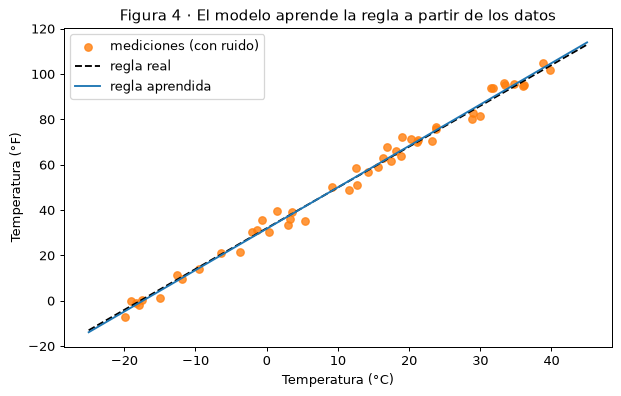

In [8]:
grid = np.linspace(-25, 45, 100)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(celsius, fahrenheit, color="tab:orange", alpha=0.8, label="mediciones (con ruido)")
ax.plot(grid, celsius_to_fahrenheit(grid), color="black", linestyle="--", label="regla real")
ax.plot(grid, design_matrix(grid) @ theta, color="tab:blue", label="regla aprendida")
ax.set_xlabel("Temperatura (°C)")
ax.set_ylabel("Temperatura (°F)")
ax.set_title("Figura 4 · El modelo aprende la regla a partir de los datos")
ax.legend()
fig.tight_layout()
plt.show()

## 4 · Con PyTorch

Hacemos el mismo ajuste con tensores de PyTorch y comparamos los resultados. Usamos `float64`
para que la comparación con NumPy sea exacta.

In [9]:
X_t = torch.tensor(design_matrix(celsius), dtype=torch.float64)
y_t = torch.tensor(fahrenheit, dtype=torch.float64).unsqueeze(1)

theta_torch = torch.linalg.lstsq(X_t, y_t).solution.squeeze(1).numpy()

print("NumPy:  ", theta)
print("PyTorch:", theta_torch)
print("same result:", np.allclose(theta, theta_torch))

NumPy:   [ 1.8262 31.7958]
PyTorch: [ 1.8262 31.7958]
same result: True


Las dos bibliotecas encuentran los mismos parámetros. En el Tema 5 resolveremos este mismo
tipo de problema de otra forma: con descenso de gradiente, el método que sí funciona para
redes neuronales.

## 5 · Experimenta

### ¿Cuántos datos hacen falta?

Mueve los deslizadores para cambiar el **número de mediciones** y el **ruido** de cada
lectura. Observa qué tan cerca quedan $w$ y $b$ de los valores reales, 1.8 y 32. Los
deslizadores funcionan al ejecutar el notebook; la figura 5 muestra tres casos fijos.

In [10]:
try:
    from ipywidgets import FloatSlider, IntSlider, interact
except ImportError:  # pragma: no cover
    interact = None


def plot_fit(ax, n_samples: int, noise: float, seed: int = SEED) -> np.ndarray:
    """Fit the linear model to fresh measurements and draw the result on ax."""
    x, y = make_measurements(n_samples, noise, np.random.default_rng(seed))
    params = fit_least_squares(x, y)
    ax.scatter(x, y, color="tab:orange", alpha=0.7, s=15)
    ax.plot(grid, celsius_to_fahrenheit(grid), color="black", linestyle="--")
    ax.plot(grid, design_matrix(grid) @ params, color="tab:blue")
    ax.set_title(f"n = {n_samples}, ruido = {noise}\nw = {params[0]:.2f}, b = {params[1]:.1f}")
    ax.set_xlabel("°C")
    ax.set_ylabel("°F")
    return params


def explore(n_samples: int = 50, noise: float = 3.0) -> None:
    """Interactive version of plot_fit."""
    _, ax = plt.subplots(figsize=(5, 4))
    plot_fit(ax, n_samples, noise)
    plt.show()


if interact is not None:
    interact(
        explore,
        n_samples=IntSlider(value=50, min=3, max=500, step=1),
        noise=FloatSlider(value=3.0, min=0.0, max=20.0, step=0.5),
    )

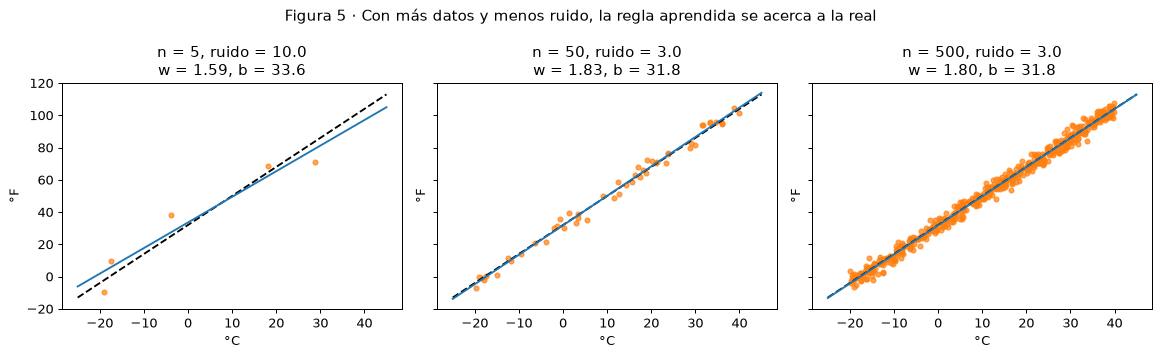

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (n_samples, noise) in zip(axes, [(5, 10.0), (50, 3.0), (500, 3.0)], strict=True):
    plot_fit(ax, n_samples, noise)
fig.suptitle("Figura 5 · Con más datos y menos ruido, la regla aprendida se acerca a la real")
fig.tight_layout()
plt.show()

## 6 · Errores comunes

- **Usar IA, machine learning y deep learning como sinónimos.** Todo deep learning es machine
  learning, y todo machine learning es IA, pero no al revés (figura 1).
- **Creer que el deep learning siempre es la mejor opción.** Con pocos datos o con tablas
  pequeñas, un modelo clásico suele funcionar igual o mejor, y es más fácil de entender.
- **Pensar que basta con tener más datos.** Si los datos tienen errores o sesgos, el modelo
  los aprende también.
- **Confundir "aprendió una regla" con "entiende el problema".** El modelo de esta lección no
  sabe qué es una temperatura: solo encontró los números que mejor ajustan los datos.
- **Calcular la inversa de $\mathbf{X}^\top\mathbf{X}$ directamente en código.** Es la
  fórmula de la sección 2.5, pero numéricamente es más estable usar `np.linalg.lstsq`, como
  en `fit_least_squares`.

## 7 · Ejercicios

**Ejercicio 1.** Clasifica cada sistema como IA sin aprendizaje, machine learning clásico o
deep learning, e indica su tipo de aprendizaje cuando aplique: (a) un filtro de spam con
reglas escritas a mano, (b) un recomendador de películas que aprende de calificaciones,
(c) un sistema de reconocimiento facial, (d) un termostato que enciende la calefacción por
debajo de 20 °C, (e) AlphaGo, (f) un asistente conversacional como ChatGPT.

*Escribe aquí tu respuesta.*

**Ejercicio 2.** Adapta el ejemplo para que el modelo aprenda a convertir **kilómetros a
millas** a partir de mediciones con ruido. ¿Qué valores de $w$ y $b$ esperas obtener y por
qué?

In [12]:
# Ejercicio 2: tu código aquí


**Ejercicio 3.** Ajusta el modelo con solo **3 mediciones** y ruido de 15. Repite con
varias semillas distintas. ¿Qué observas en los valores de $w$ y $b$? Explícalo con lo que
viste en el experimento de la sección 5.

In [13]:
# Ejercicio 3: tu código aquí


**Ejercicio 4.** Explica con tus palabras la diferencia entre **diseñar características a
mano** y **aprender representaciones**. Da un ejemplo de cada una para un problema que te
interese.

*Escribe aquí tu respuesta.*

**Ejercicio 5.** Elige uno de los hitos de la figura 3 e investiga qué problema resolvió y
por qué fue importante. Cita tus fuentes.

*Escribe aquí tu respuesta.*

## 8 · Para profundizar

- **Goodfellow, Bengio y Courville (2016), capítulo 1:** introducción y perspectiva histórica.
- **Prince (2023), capítulo 1:** panorama del aprendizaje supervisado, no supervisado y por
  refuerzo.
- **Chollet y Watson (2025), capítulo 1:** qué es el deep learning.
- **Mitchell (1997), capítulo 1:** la definición de aprendizaje con tarea, experiencia y
  desempeño.
- **Russell y Norvig (2021), capítulo 1:** qué es la inteligencia artificial.

Artículo original:
- Samuel, A. L. (1959). Some studies in machine learning using the game of checkers. *IBM
  Journal of Research and Development*, 3(3), 210–229.

Referencias completas en [SYLLABUS.md](../../SYLLABUS.md) y
[docs/REFERENCES.md](../../docs/REFERENCES.md).

---
*Texto y figuras: [CC BY 4.0](../../LICENSE-CONTENT). Código: [MIT](../../LICENSE).*